# **UTP 1 - Multilayer Perceptron (tanpa Backpropagation)**

**Waktu: 120 menit** | Sifat: open notebook, tanpa internet selain untuk mengunggah file | Dikerjakan individu

### Studi kasus
Sebuah pabrik memantau kondisi tangki reaktor menggunakan dua sensor: **suhu** (°C) dan **tekanan** (hPa). Tangki dinyatakan **ABNORMAL (target = 1)** apabila tepat salah satu sensor bernilai tinggi (suhu tinggi-tekanan rendah, atau suhu rendah-tekanan tinggi), dan **NORMAL (target = -1)** apabila keduanya rendah atau keduanya tinggi. Pola ini adalah versi nyata dari masalah **XOR**, sehingga tidak dapat dipisahkan oleh satu garis lurus.

Dataset `data_utp1.csv` berisi 480 pengamatan. Data mengandung **derau pengukuran** dan sekitar **4% label yang salah tercatat** oleh operator.

### Model yang digunakan
MLP dengan arsitektur **2 input -> `hidden_size` neuron (sigmoid) -> 1 output (linear)**, masing-masing lapisan memiliki bias.

Pada UTP ini **tidak digunakan backpropagation**:
- Bobot **input -> hidden** diinisialisasi acak lalu **dibekukan** (tidak pernah diubah). Hidden layer berfungsi sebagai pengubah fitur (2 fitur menjadi `hidden_size` fitur non-linear).
- Hanya bobot **hidden -> output** yang dilatih, menggunakan **aturan delta (Widrow-Hoff)** seperti pada ADALINE.

### Ketentuan
1. Gunakan `SEED = 42` dan jangan mengubah sel yang bertanda **JANGAN DIUBAH**.
2. Lengkapi setiap bagian bertanda `# TODO`. Notebook harus dapat dijalankan ulang dari awal (Runtime > Run all) tanpa error.
3. Jawaban analisis **wajib** merujuk pada angka/grafik yang dihasilkan notebook Anda sendiri. Jawaban tanpa bukti dari output tidak diberi nilai penuh.
4. Dilarang menggunakan library jaringan saraf (Keras, PyTorch, `sklearn.neural_network`). Implementasi manual dengan NumPy.

### Bobot penilaian
| Bagian | Bobot |
|---|---|
| Tugas 1 - Pra-pemrosesan | 10 |
| Tugas 2 - Fungsi aktivasi | 10 |
| Tugas 3 - `mlp_fit` (forward + aturan delta) | 15 |
| Tugas 4 - `mlp_predict` | 10 |
| Tugas 5 - Grid search | 5 |
| Soal analisis 1-5 (masing-masing 10) | 50 |

In [ ]:
#JANGAN DIUBAH
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, ParameterGrid

SEED = 42
np.random.seed(SEED)

In [ ]:
#JANGAN DIUBAH - unggah file data_utp1.csv
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    pass

Saving data_utp1.csv to data_utp1 (1).csv


## Eksplorasi data

     suhu   tekanan  target
0  21.259  1169.571       1
1  39.824   969.188       1
2  43.529  1174.476      -1
3  22.513  1140.166       1
4  30.557  1238.131      -1

         suhu  tekanan  target
count  480.00   480.00   480.0
mean    32.61  1050.45     0.0
std      7.98   157.91     1.0
min     14.88   745.54    -1.0
25%     25.11   908.17    -1.0
50%     33.38  1043.64     1.0
75%     39.94  1200.55     1.0
max     46.85  1374.76     1.0

Distribusi target: {1: 241, -1: 239}


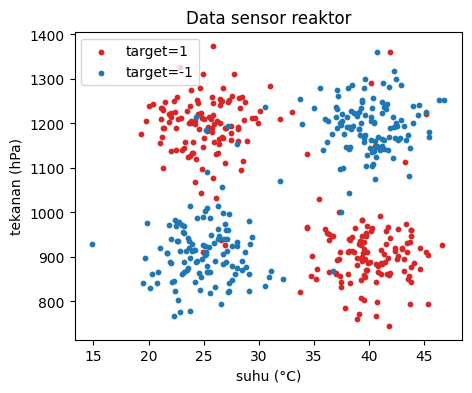

In [ ]:
#JANGAN DIUBAH
df = pd.read_csv('data_utp1.csv')
print(df.head())
print()
print(df.describe().round(2))
print()
print('Distribusi target:', df['target'].value_counts().to_dict())

plt.figure(figsize=(5, 4))
for t, c in [(1, 'tab:red'), (-1, 'tab:blue')]:
    s = df[df['target'] == t]
    plt.scatter(s['suhu'], s['tekanan'], s=10, c=c, label=f'target={t}')
plt.xlabel('suhu (°C)'); plt.ylabel('tekanan (hPa)'); plt.legend(); plt.title('Data sensor reaktor')
plt.show()

## Tugas 1 - Pra-pemrosesan (10 poin)

Data sudah dibagi menjadi **train (64%)**, **validasi (16%)**, dan **test (20%)** secara stratified.

Lengkapi fungsi `standardize(X, mean, std)` yang mengubah setiap fitur menjadi z-score: $z = (x - \mu)/\sigma$.

**Penting:** `mean` dan `std` harus dihitung **hanya dari data train**, lalu dipakai untuk mentransformasi train, validasi, dan test.

In [ ]:
#JANGAN DIUBAH - pembagian data
X = df[['suhu', 'tekanan']].to_numpy(dtype=float)
y = df['target'].to_numpy().reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
print('train:', X_train.shape, '| val:', X_val.shape, '| test:', X_test.shape)

train: (307, 2) | val: (77, 2) | test: (96, 2)


In [ ]:
def standardize(X, mean, std):
    # TODO: lengkapi kode di sini
    return (X - mean) / std

# Hitung mean dan std dari data TRAIN saja
# TODO: lengkapi kode di sini
mu = np.mean(X_train, axis=0)
sigma = np.std(X_train, axis=0)

Xs_train = standardize(X_train, mu, sigma)
Xs_val   = standardize(X_val, mu, sigma)
Xs_test  = standardize(X_test, mu, sigma)

print('mean train setelah standarisasi:', Xs_train.mean(axis=0).round(4))
print('std  train setelah standarisasi:', Xs_train.std(axis=0).round(4))

mean train setelah standarisasi: [ 0. -0.]
std  train setelah standarisasi: [1. 1.]


## Tugas 2 - Fungsi aktivasi (10 poin)

Lengkapi dua fungsi berikut. Keduanya harus **ter-vektorisasi** (bisa menerima array NumPy, bukan hanya skalar).

1. `percep_step(v, th=0)` - fungsi tangga bipolar dengan zona ragu: menghasilkan `1` jika `v > th`, `-1` jika `v < -th`, dan `0` jika `-th <= v <= th`. Gunakan `np.where`, bukan `if`.
2. `sigmoid(x)` - $\sigma(x) = 1/(1+e^{-x})$. Cegah overflow dengan `np.clip(x, -500, 500)` sebelum `np.exp`.

In [ ]:
def percep_step(v, th=0):
    # TODO: lengkapi kode di sini
    return np.where(v > th, 1, np.where(v < -th, -1, 0))

def sigmoid(x):
    # TODO: lengkapi kode di sini
    x_clipped = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x_clipped))

#JANGAN DIUBAH - uji cepat
print(percep_step(np.array([-0.5, -0.1, 0.0, 0.1, 0.5]), th=0.2))  # harus [-1  0  0  0  1]
print(sigmoid(np.array([0.0, 1000.0, -1000.0])))                     # harus [0.5 1.  0. ] tanpa warning

[-1  0  0  0  1]
[5.00000000e-001 1.00000000e+000 7.12457641e-218]


## Tugas 3 - Pelatihan MLP (15 poin)

Inisialisasi bobot **sudah disediakan**:
- `W1`, `b1` (input -> hidden): uniform $[-\text{scale}, \text{scale}]$, **tidak dilatih**.
- `W2`, `b2` (hidden -> output): nol, **dilatih**.

Tugas Anda melengkapi isi loop untuk setiap sampel `x` dengan target `t`:
1. **Forward hidden:** $h = \sigma(x W_1 + b_1)$
2. **Forward output (linear):** $o = h W_2 + b_2$
3. **Galat:** $e = t - o$, lalu tambahkan $e^2$ ke `sse`
4. **Aturan delta (hanya lapisan output):** $W_2 \mathrel{+}= \alpha\, h^T e$ (gunakan `np.outer(h, e)`), dan $b_2 \mathrel{+}= \alpha\, e$

`W1` dan `b1` **tidak boleh** diubah di dalam loop. Riwayat MSE per epoch disimpan di `history`.

**Catatan:** keluaran linear (kontinu) dipakai saat pelatihan; fungsi tangga hanya dipakai saat prediksi.

In [ ]:
def mlp_fit(X, T, hidden_size, learning_rate=0.01, max_epoch=100, scale=3.0, seed=SEED):
    #JANGAN DIUBAH - inisialisasi
    rng = np.random.default_rng(seed)
    W1 = rng.uniform(-scale, scale, (X.shape[1], hidden_size))   # dibekukan
    b1 = rng.uniform(-scale, scale, hidden_size)                 # dibekukan
    W2 = np.zeros((hidden_size, 1))                              # dilatih
    b2 = np.zeros(1)                                             # dilatih

    history = []
    for epoch in range(max_epoch):
        sse = 0.0
        for i in rng.permutation(len(X)):
            x, t = X[i], T[i]
            # forward pass, hitung galat, dan update W2 serta b2
            # TODO: lengkapi kode di sini
            h = sigmoid(x @ W1 + b1)
            o = h @ W2 + b2
            e = t - o
            sse += float(e ** 2)
            W2 += learning_rate * np.outer(h, e)
            b2 += learning_rate * e
        history.append(sse / len(X))

    return {'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2, 'history': history}

## Tugas 4 - Prediksi (10 poin)

Lengkapi `mlp_predict(X, model, th=0)`: lakukan forward pass secara **vektor (tanpa loop)** untuk seluruh baris `X` (hidden sigmoid, lalu output linear), kemudian terapkan `percep_step` dengan threshold `th`. Kembalikan array 1 dimensi.

In [ ]:
def mlp_predict(X, model, th=0):
    # TODO: lengkapi kode di sini
    W1, b1 = model['W1'], model['b1']
    W2, b2 = model['W2'], model['b2']
    h = sigmoid(X @ W1 + b1)
    o = h @ W2 + b2
    return percep_step(o, th).ravel()

#JANGAN DIUBAH - fungsi bantu
def calc_accuracy(y_true, y_pred):
    return float(np.mean(np.ravel(y_true) == np.ravel(y_pred)))

def plot_decision_boundary(X, target, model, title=''):
    h = .02
    x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
    y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = mlp_predict(np.c_[xx.ravel(), yy.ravel()], model).reshape(xx.shape)
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.6)
    plt.scatter(X[:, 0], X[:, 1], c=np.ravel(target), cmap=plt.cm.Spectral, s=10, edgecolors='k', linewidths=.2)
    plt.xlabel('suhu (z-score)'); plt.ylabel('tekanan (z-score)'); plt.title(title)

## Tugas 5 - Grid search (5 poin)

Lakukan grid search pada kombinasi di bawah. Untuk setiap kombinasi: latih pada `Xs_train`, hitung akurasi **train** dan **validasi**, serta MSE epoch terakhir. Simpan hasil sebagai DataFrame `hasil` (kolom: `hidden_size`, `learning_rate`, `max_epoch`, `acc_train`, `acc_val`, `mse_akhir`).

Pilih model terbaik berdasarkan **`acc_val` tertinggi** (jika seri, pilih yang muncul lebih dulu). Data **test tidak boleh** dipakai untuk memilih model.

Catatan: beberapa kombinasi dapat menghasilkan `nan`. Ini disengaja dan akan dibahas di soal analisis; `np.errstate` hanya menyembunyikan peringatannya.

In [ ]:
param_grid = {
    'hidden_size':   [2, 4, 8, 16, 32],
    'learning_rate': [0.001, 0.01, 0.1, 0.5],
    'max_epoch':     [50, 200],
}

records = []
best_model, best_params, best_val = None, None, -1

with np.errstate(over='ignore', invalid='ignore'):
    for params in ParameterGrid(param_grid):
        # TODO: lengkapi kode di sini
        m = mlp_fit(Xs_train, y_train,
                    hidden_size=params['hidden_size'],
                    learning_rate=params['learning_rate'],
                    max_epoch=params['max_epoch'])

        y_pred_train = mlp_predict(Xs_train, m)
        y_pred_val = mlp_predict(Xs_val, m)

        acc_train = calc_accuracy(y_train, y_pred_train)
        acc_val = calc_accuracy(y_val, y_pred_val)
        mse_akhir = m['history'][-1]

        records.append({
            'hidden_size': params['hidden_size'],
            'learning_rate': params['learning_rate'],
            'max_epoch': params['max_epoch'],
            'acc_train': acc_train,
            'acc_val': acc_val,
            'mse_akhir': mse_akhir
        })

        if acc_val > best_val:
            best_val = acc_val
            best_params = params
            best_model = m

hasil = pd.DataFrame(records)
print(hasil.round(3).to_string())

/tmp/ipykernel_3476/1902768563.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sse += float(e ** 2)


    hidden_size  learning_rate  max_epoch  acc_train  acc_val  mse_akhir
0             2          0.001         50      0.681    0.649      0.856
1             2          0.001        200      0.681    0.649      0.845
2             2          0.010         50      0.668    0.649      0.854
3             2          0.010        200      0.671    0.649      0.857
4             2          0.100         50      0.671    0.649      0.913
5             2          0.100        200      0.521    0.519      0.940
6             2          0.500         50      0.502    0.506      1.545
7             2          0.500        200      0.498    0.494      1.648
8             4          0.001         50      0.879    0.831      0.644
9             4          0.001        200      0.945    0.909      0.336
10            4          0.010         50      0.945    0.922      0.290
11            4          0.010        200      0.948    0.922      0.287
12            4          0.100         50      0.94

Akurasi validasi terbaik per (hidden_size, learning_rate):
learning_rate  0.001  0.010  0.100  0.500
hidden_size                              
2              0.649  0.649  0.649  0.506
4              0.909  0.922  0.935  0.922
8              0.909  0.948  0.909  0.000
16             0.935  0.948  0.948  0.000
32             0.948  0.961  0.961  0.000

Parameter terbaik : {'hidden_size': 32, 'learning_rate': 0.01, 'max_epoch': 200}
Akurasi train     : 0.9479
Akurasi validasi  : 0.961
Akurasi test      : 0.9583


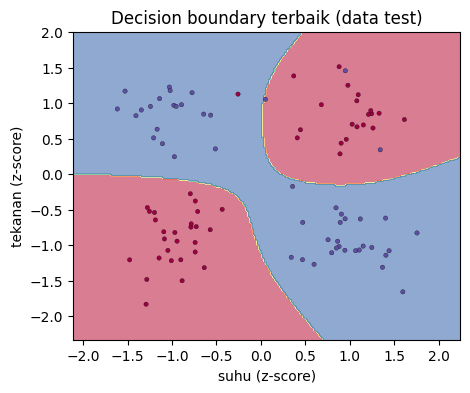

In [ ]:
#JANGAN DIUBAH - ringkasan dan evaluasi model terbaik
print('Akurasi validasi terbaik per (hidden_size, learning_rate):')
print(hasil.pivot_table(index='hidden_size', columns='learning_rate', values='acc_val', aggfunc='max').round(3))
print()
acc_test = calc_accuracy(y_test, mlp_predict(Xs_test, best_model))
print('Parameter terbaik :', best_params)
print('Akurasi train     :', round(calc_accuracy(y_train, mlp_predict(Xs_train, best_model)), 4))
print('Akurasi validasi  :', round(best_val, 4))
print('Akurasi test      :', round(acc_test, 4))

plt.figure(figsize=(5, 4))
plot_decision_boundary(Xs_test, y_test, best_model, 'Decision boundary terbaik (data test)')
plt.show()

## Eksperimen pendukung analisis

Jalankan sel-sel berikut **tanpa mengubah kode**. Hasilnya dipakai untuk menjawab soal analisis.

Tanpa hidden layer -> akurasi test: 0.4479


/tmp/ipykernel_3476/1902768563.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sse += float(e ** 2)


hidden_size = 2    -> akurasi test: 0.6771
hidden_size = 32   -> akurasi test: 0.9583


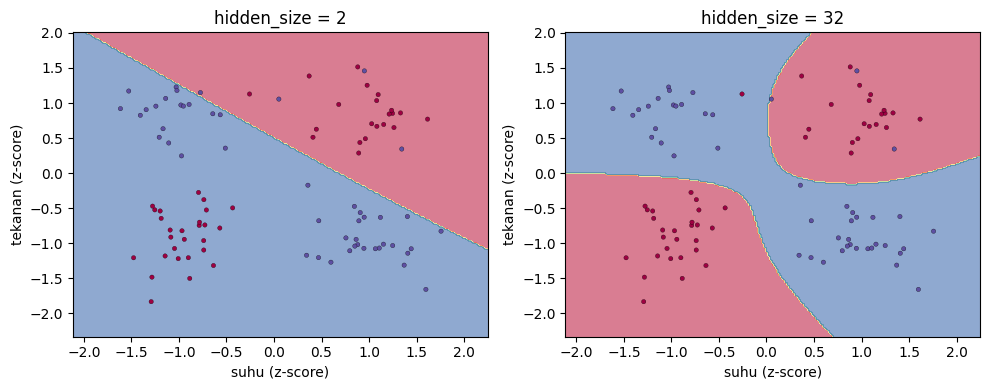

In [ ]:
#JANGAN DIUBAH - Eksperimen A: tanpa hidden layer vs hidden_size kecil vs model terbaik
def delta_rule_linear(X, T, learning_rate=0.01, max_epoch=200, seed=SEED):
    # model tanpa hidden layer: o = xW + b, dilatih dengan aturan delta yang sama
    rng = np.random.default_rng(seed)
    W, b = np.zeros((X.shape[1], 1)), np.zeros(1)
    for _ in range(max_epoch):
        for i in rng.permutation(len(X)):
            e = T[i] - (X[i] @ W + b)
            W += learning_rate * np.outer(X[i], e); b += learning_rate * e
    return W, b

W_lin, b_lin = delta_rule_linear(Xs_train, y_train)
print('Tanpa hidden layer -> akurasi test:', round(calc_accuracy(y_test, percep_step(Xs_test @ W_lin + b_lin).ravel()), 4))

m2 = mlp_fit(Xs_train, y_train, hidden_size=2, learning_rate=0.01, max_epoch=200)
print('hidden_size = 2    -> akurasi test:', round(calc_accuracy(y_test, mlp_predict(Xs_test, m2)), 4))
print(f"hidden_size = {best_params['hidden_size']:<2}   -> akurasi test:", round(acc_test, 4))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plot_decision_boundary(Xs_test, y_test, m2, 'hidden_size = 2')
plt.subplot(1, 2, 2); plot_decision_boundary(Xs_test, y_test, best_model, f"hidden_size = {best_params['hidden_size']}")
plt.tight_layout(); plt.show()

In [ ]:
#JANGAN DIUBAH - Eksperimen B: pelatihan TANPA standarisasi
with np.errstate(over='ignore', invalid='ignore'):
    m_raw = mlp_fit(X_train, y_train, **best_params)
print('Tanpa standarisasi -> akurasi test:', round(calc_accuracy(y_test, mlp_predict(X_test, m_raw)), 4))

for nama, Xh, m in [('raw', X_train, m_raw), ('std', Xs_train, best_model)]:
    H = sigmoid(Xh @ m['W1'] + m['b1'])
    jenuh = np.mean((H < 0.01) | (H > 0.99))
    pola_unik = len(np.unique(np.round(H, 2), axis=0))
    print(f'[{nama}] proporsi output hidden jenuh (<0.01 atau >0.99): {jenuh:.3f} | pola hidden unik (dibulatkan 2 desimal): {pola_unik} dari {len(H)} sampel')

/tmp/ipykernel_3476/1902768563.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sse += float(e ** 2)


Tanpa standarisasi -> akurasi test: 0.5
[raw] proporsi output hidden jenuh (<0.01 atau >0.99): 0.999 | pola hidden unik (dibulatkan 2 desimal): 9 dari 307 sampel
[std] proporsi output hidden jenuh (<0.01 atau >0.99): 0.096 | pola hidden unik (dibulatkan 2 desimal): 307 dari 307 sampel


/tmp/ipykernel_3476/1902768563.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sse += float(e ** 2)


lr=0.001  MSE ep10=0.7609  MSE ep200=0.2107  acc_val=0.935
lr=0.01   MSE ep10=0.25  MSE ep200=0.202  acc_val=0.948
lr=0.1    MSE ep10=0.3276  MSE ep200=0.2823  acc_val=0.948
lr=0.5    MSE ep10=nan  MSE ep200=nan  acc_val=0.000


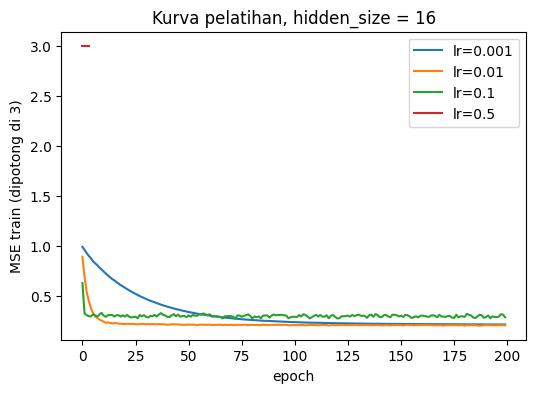


Rata-rata ||[h, 1]||^2 (panjang kuadrat vektor masukan lapisan output) dan batas lr ~ 2 / ||[h, 1]||^2:
  hidden_size=2   ||[h,1]||^2 =   1.98   2/||[h,1]||^2 = 1.009
  hidden_size=4   ||[h,1]||^2 =   2.60   2/||[h,1]||^2 = 0.769
  hidden_size=8   ||[h,1]||^2 =   4.87   2/||[h,1]||^2 = 0.411
  hidden_size=16  ||[h,1]||^2 =   6.94   2/||[h,1]||^2 = 0.288
  hidden_size=32  ||[h,1]||^2 =  11.27   2/||[h,1]||^2 = 0.177


In [ ]:
#JANGAN DIUBAH - Eksperimen C: learning rate, kurva MSE, dan batas stabilitas aturan delta
plt.figure(figsize=(6, 4))
for lr in [0.001, 0.01, 0.1, 0.5]:
    with np.errstate(over='ignore', invalid='ignore'):
        m = mlp_fit(Xs_train, y_train, hidden_size=16, learning_rate=lr, max_epoch=200)
    hist = np.array(m['history'])
    print(f'lr={lr:<6} MSE ep10={hist[9]:.4g}  MSE ep200={hist[-1]:.4g}  acc_val={calc_accuracy(y_val, mlp_predict(Xs_val, m)):.3f}')
    plt.plot(np.clip(hist, 0, 3), label=f'lr={lr}')
plt.xlabel('epoch'); plt.ylabel('MSE train (dipotong di 3)'); plt.legend(); plt.title('Kurva pelatihan, hidden_size = 16')
plt.show()

print()
print('Rata-rata ||[h, 1]||^2 (panjang kuadrat vektor masukan lapisan output) dan batas lr ~ 2 / ||[h, 1]||^2:')
for hs in [2, 4, 8, 16, 32]:
    m = mlp_fit(Xs_train, y_train, hidden_size=hs, max_epoch=0)
    H = sigmoid(Xs_train @ m['W1'] + m['b1'])
    norm2 = np.mean(np.sum(H ** 2, axis=1) + 1)
    print(f'  hidden_size={hs:<3} ||[h,1]||^2 = {norm2:6.2f}   2/||[h,1]||^2 = {2 / norm2:.3f}')

In [ ]:
#JANGAN DIUBAH - Eksperimen D: skala bobot acak hidden layer (hidden_size = 16, lr = 0.01, 200 epoch)
rows = []
for sc in [0.1, 1, 3, 10, 30]:
    m = mlp_fit(Xs_train, y_train, hidden_size=16, learning_rate=0.01, max_epoch=200, scale=sc)
    H = sigmoid(Xs_train @ m['W1'] + m['b1'])
    rows.append({'scale': sc,
                 'acc_train': calc_accuracy(y_train, mlp_predict(Xs_train, m)),
                 'acc_val': calc_accuracy(y_val, mlp_predict(Xs_val, m)),
                 'rentang h (min-max)': f'{H.min():.2f}-{H.max():.2f}',
                 'proporsi h jenuh': np.mean((H < 0.01) | (H > 0.99))})
print(pd.DataFrame(rows).round(3).to_string(index=False))

print()
print('Variasi seed (hidden_size = 4, scale = 3, lr = 0.01, 200 epoch):')
for s in [0, 1, 2, 3, 42]:
    m = mlp_fit(Xs_train, y_train, hidden_size=4, learning_rate=0.01, max_epoch=200, seed=s)
    print(f'  seed={s:<3} acc_val={calc_accuracy(y_val, mlp_predict(Xs_val, m)):.3f}')

/tmp/ipykernel_3476/1902768563.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sse += float(e ** 2)


 scale  acc_train  acc_val rentang h (min-max)  proporsi h jenuh
   0.1      0.498    0.494           0.43-0.56             0.000
   1.0      0.954    0.948           0.05-0.92             0.000
   3.0      0.954    0.948           0.00-1.00             0.115
  10.0      0.945    0.922           0.00-1.00             0.650
  30.0      0.938    0.896           0.00-1.00             0.863

Variasi seed (hidden_size = 4, scale = 3, lr = 0.01, 200 epoch):


/tmp/ipykernel_3476/1902768563.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sse += float(e ** 2)


  seed=0   acc_val=0.896
  seed=1   acc_val=0.831
  seed=2   acc_val=0.896
  seed=3   acc_val=0.870
  seed=42  acc_val=0.922


In [ ]:
#JANGAN DIUBAH - Eksperimen E: pengaruh threshold th pada prediksi (model terbaik, data test)
rows = []
for th in [0, 0.2, 0.4, 0.6, 0.8]:
    p = mlp_predict(Xs_test, best_model, th=th)
    decided = p != 0
    rows.append({'th': th,
                 'akurasi (0 dihitung salah)': calc_accuracy(y_test, p),
                 'proporsi ragu (output 0)': (~decided).mean(),
                 'akurasi pada yang diputuskan': calc_accuracy(y_test.ravel()[decided], p[decided]) if decided.any() else np.nan})
print(pd.DataFrame(rows).round(3).to_string(index=False))

p0 = mlp_predict(Xs_test, best_model, th=0)
print()
print('Matriks konfusi (th = 0), baris = aktual, kolom = prediksi:')
print(pd.crosstab(pd.Series(y_test.ravel(), name='aktual'), pd.Series(p0, name='prediksi')))

 th  akurasi (0 dihitung salah)  proporsi ragu (output 0)  akurasi pada yang diputuskan
0.0                       0.958                     0.000                         0.958
0.2                       0.948                     0.021                         0.968
0.4                       0.906                     0.062                         0.967
0.6                       0.833                     0.156                         0.988
0.8                       0.625                     0.365                         0.984

Matriks konfusi (th = 0), baris = aktual, kolom = prediksi:
prediksi  -1   1
aktual          
-1        47   1
 1         3  45


# **Soal Analisis** (masing-masing 10 poin)

Jawab setiap soal di sel jawaban di bawahnya. Rujuk angka spesifik dari output notebook Anda.

**Soal 1 - Pemilihan model dan generalisasi.**
Laporkan konfigurasi terbaik serta akurasi train, validasi, dan test-nya. (a) Mengapa model dipilih berdasarkan akurasi validasi, bukan akurasi train atau test? (b) Dataset diketahui memiliki sekitar 4% label yang salah. Berapa kira-kira batas atas akurasi test yang realistis, dan apa yang patut dicurigai jika sebuah model mencapai akurasi train 100%? (c) Pada UTP sebelumnya, akurasi dihitung pada data yang sama dengan data latih (4 titik XOR/AND). Apa kelemahan evaluasi seperti itu?

**Jawaban:**

Konfigurasi terbaik adalah hidden_size = 32, learning_rate = 0.01, dan max_epoch = 200 dengan akurasi train 0.9479, validasi 0.961, dan test 0.9583. (a) Model dipilih berdasarkan akurasi validasi karena akurasi train terlalu optimis (diukur pada data yang dipakai melatih), sedangkan data test harus tetap tidak tersentuh agar menjadi estimasi jujur untuk data baru; jika test dipakai memilih model, terjadi kebocoran informasi. (b) Dengan sekitar 4% label salah, batas atas akurasi test yang realistis kira-kira 96%, dan test kita (95.83%) sudah hampir mencapainya; akurasi train 100% patut dicurigai sebagai overfitting (model menghafal label salah dan derau) atau adanya kebocoran data. (c) Mengevaluasi pada data yang sama dengan data latih (4 titik XOR/AND) tidak mengukur kemampuan generalisasi, tidak bisa mendeteksi overfitting, dan model yang hanya menghafal pun akan tampak sempurna.

**Soal 2 - Peran hidden layer.**
Gunakan Eksperimen A dan tabel pivot grid search. (a) Mengapa model tanpa hidden layer gagal pada data ini, padahal aturan pelatihannya sama persis? (b) Hidden layer pada UTP ini **tidak dilatih**. Jelaskan mengapa model tetap dapat memecahkan XOR, dan mengapa dibutuhkan lebih banyak neuron hidden dibandingkan minimum teoretis (2 neuron) untuk XOR. (c) Apa kelemahan utama membekukan bobot hidden dibandingkan melatihnya? Rujuk hasil variasi seed pada Eksperimen D.

**Jawaban:**

(a) Model tanpa hidden layer hanya fungsi linear sehingga batas keputusannya satu garis lurus, padahal pola XOR tidak dapat dipisahkan secara linear; akibatnya akurasi test hanya 0.4479, di bawah tebakan acak, walaupun aturan delta yang dipakai sama persis. (b) Hidden layer acak yang dibekukan tetap berguna karena memetakan 2 fitur menjadi banyak fitur non-linear sehingga kelas menjadi terpisah linear di ruang fitur tersebut, dan lapisan output cukup dilatih dengan aturan delta; namun karena arah dan posisi garis tiap neuron ditentukan acak (tidak disetel), dibutuhkan lebih banyak neuron dari minimum teoretis 2, terbukti hidden_size = 2 hanya mencapai akurasi validasi 0.649 sedangkan hidden_size = 32 mencapai 0.961 pada tabel pivot. (c) Kelemahan utama membekukan bobot hidden adalah hasil sangat bergantung pada keberuntungan inisialisasi; pada Eksperimen D dengan hidden_size = 4, akurasi validasi berubah dari 0.831 (seed 1) sampai 0.922 (seed 42) hanya karena seed berbeda.

**Soal 3 - Standarisasi dan saturasi sigmoid.**
Gunakan hasil Eksperimen B dan D. (a) Jelaskan mengapa model tanpa standarisasi berkinerja buruk, dikaitkan dengan skala fitur `tekanan`, proporsi output hidden yang jenuh, dan jumlah pola hidden unik. (b) Pada Eksperimen D, mengapa skala bobot yang terlalu kecil maupun terlalu besar sama-sama menurunkan akurasi? (c) Mengapa `mean` dan `std` hanya boleh dihitung dari data train? Sebutkan istilah untuk pelanggaran ini dan dampaknya.

**Jawaban:**

(a) Tanpa standarisasi, nilai tekanan sangat besar (sekitar 745 sampai 1375 hPa) sehingga pra-aktivasi hidden bernilai ratusan sampai ribuan dan sigmoid jenuh: proporsi output jenuh 0.999 (dibanding 0.096 dengan standarisasi) dan pola hidden unik hanya 9 dari 307 sampel (dibanding 307 dari 307), sehingga fitur hidden hampir tidak informatif dan akurasi test turun menjadi 0.5. (b) Skala bobot yang terlalu kecil (0.1) membuat pra-aktivasi dekat nol sehingga h hampir konstan (0.43 sampai 0.56) dan sigmoid bekerja hampir linear, sehingga XOR gagal diselesaikan (akurasi validasi 0.494); skala yang terlalu besar (10 dan 30) membuat sigmoid jenuh (proporsi jenuh 0.650 dan 0.863) sehingga fitur menjadi hampir biner dan kasar, dan akurasi validasi turun menjadi 0.922 dan 0.896, sedangkan skala menengah (1 sampai 3) terbaik dengan 0.948. (c) Mean dan std hanya boleh dihitung dari data train karena val dan test mewakili data baru yang belum diketahui; jika ikut dihitung, terjadi data leakage yang membuat estimasi performa menjadi terlalu optimis.

**Soal 4 - Learning rate dan divergensi.**
Gunakan Eksperimen C dan tabel grid search. (a) Bagaimana pengaruh learning rate terhadap kecepatan konvergensi dan stabilitas MSE? (b) Pada grid search, `learning_rate = 0.5` menghasilkan `nan` untuk `hidden_size` besar tetapi tidak untuk `hidden_size` kecil. Jelaskan fenomena ini menggunakan nilai $\|[h,1]\|^2$ dan batas $2/\|[h,1]\|^2$ yang dicetak pada Eksperimen C. (c) Learning rate mana yang Anda rekomendasikan dan mengapa?

**Jawaban:**

(a) Learning rate kecil (0.001) stabil tetapi lambat (MSE epoch ke-10 masih 0.7609 dan baru 0.2107 di epoch 200), learning rate 0.01 cepat dan stabil (MSE 0.25 di epoch ke-10 dan 0.202 di epoch 200), learning rate 0.1 cepat tetapi lebih bergejolak dengan MSE akhir lebih tinggi (0.2823), dan learning rate 0.5 diverge sehingga MSE menjadi nan. (b) Aturan delta stabil hanya jika learning rate lebih kecil dari 2/||[h,1]||^2, dan nilai ||[h,1]||^2 membesar seiring bertambahnya neuron hidden (1.98 untuk hidden_size 2, 2.60 untuk 4, 4.87 untuk 8, 6.94 untuk 16, dan 11.27 untuk 32) sehingga batasnya mengecil (1.009, 0.769, 0.411, 0.288, 0.177); karena 0.5 melebihi batas pada hidden_size 8, 16, dan 32, galat membesar di setiap langkah hingga overflow menjadi nan, sedangkan pada hidden_size 2 dan 4 learning rate 0.5 masih di bawah batas sehingga tidak nan (walau hasilnya buruk karena mendekati batas). (c) Saya merekomendasikan learning rate 0.01 karena konvergen cepat, MSE akhir terendah, jauh di bawah batas stabilitas, dan menjadi bagian dari konfigurasi terbaik pada grid search.

**Soal 5 - Threshold dan opsi menolak (reject option).**
Gunakan tabel Eksperimen E. (a) Jelaskan trade-off antara akurasi keseluruhan, proporsi prediksi ragu, dan akurasi pada sampel yang diputuskan ketika `th` dinaikkan. (b) Pada konteks pemantauan reaktor, kesalahan mana yang lebih berbahaya: reaktor ABNORMAL diprediksi NORMAL atau sebaliknya? Usulkan nilai `th` dan kebijakan untuk output `0`, beserta alasannya. (c) Jika Anda ingin menurunkan kesalahan jenis yang lebih berbahaya tanpa zona ragu, modifikasi apa yang dapat dilakukan pada aturan keputusan `percep_step`?

**Jawaban:**

(a) Semakin besar th, semakin banyak sampel yang masuk zona ragu (0% pada th 0 menjadi 36.5% pada th 0.8) sehingga akurasi keseluruhan turun dari 0.958 menjadi 0.625, tetapi akurasi pada sampel yang diputuskan naik dari 0.958 menjadi sekitar 0.984 sampai 0.988 karena model hanya memutuskan saat yakin; jadi ada pertukaran antara cakupan keputusan dan keandalan. (b) Kesalahan yang lebih berbahaya adalah reaktor ABNORMAL diprediksi NORMAL (bahaya tidak terdeteksi), dan pada matriks konfusi ada 3 kasus seperti ini dibanding 1 kasus false alarm; saya mengusulkan th sekitar 0.4 (zona ragu 6.2% dengan akurasi 0.967 pada yang diputuskan) dan output 0 diperlakukan sebagai potensi ABNORMAL yang diperiksa ulang secara manual (kebijakan aman). (c) Tanpa zona ragu, aturan keputusan dapat dibuat asimetris, misalnya memprediksi ABNORMAL jika o > -θ (θ > 0) sehingga batas bergeser ke sisi NORMAL dan kasus ABNORMAL yang terlewat berkurang, dengan konsekuensi false alarm bertambah.